# Шаг 5. Внимание (attention) своими руками

Биграмма видит одну предыдущую букву — этого мало. Хочется, чтобы каждый токен мог «посмотреть» на **все** предыдущие
и взять от каждого столько, сколько ему нужно. Это и делает **внимание** — главная деталь трансформеров (буква T в GPT).

**Идея по шагам:**
1. **Просто среднее.** Каждый токен = среднее себя и всех предыдущих. Информация из прошлого уже приходит, но все слова равноправны.
2. **Внимание.** Веса среднего зависят от самих слов. Каждое слово делает три вектора:
   - **Q** (*query*, запрос) — «что я ищу»;
   - **K** (*key*, ключ) — «что я могу предложить»;
   - **V** (*value*, значение) — «что я отдам, если на меня посмотрят».

   Вес = насколько запрос подходит к ключу: скалярное произведение `Q·K`, затем softmax по строке.
3. **Маска.** Будущее смотреть нельзя — иначе модель «подсмотрит» ответ. Запрещённым клеткам ставим −∞, после softmax они станут 0.
4. **Несколько голов.** Несколько независимых вниманий: одна голова следит за рифмой, другая — за началом строки и т.д.

Формула целиком: `softmax(Q·Kᵀ / √d + маска) · V`.

**Аналогия.** Ученик ищет решение задачи 3 (запрос). У каждого одноклассника на парте табличка «я решил задачи 1–3» (ключ),
а в тетради — само решение (значение). Ученик списывает больше у тех, чья табличка лучше подходит к вопросу.

**Структура примера (алгоритм):**
1. Строим маску и веса «просто среднее».
2. Считаем внимание на пальцах: один запрос, три ключа — всё можно проверить в уме.
3. Считаем Q, K, V, оценки, маску, softmax — и проверяем со встроенной функцией PyTorch.
4. Выясняем, зачем делить на √d.
5. Рисуем обе таблицы весов.
6. Вручную настраиваем внимание, которое ищет похожие слова.
7. Проверяем, что внимание не знает порядка слов.
8. Смотрим на формы тензоров для нескольких голов.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session05")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

## Общий модуль `common.py`

Во всех примерах сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `load_names()`, `load_text()` | русские имена из `names.txt` и «Евгений Онегин» (главы 1–8) из `onegin.txt` |
| `CharTokenizer(text)` | словарь символов: `encode` — строка → номера, `decode` — номера → строка, `vocab_size` — размер словаря |
| `name_tokenizer`, `bigram_pairs`, `bigram_counts` | словарь для имён (точка `.` — начало/конец имени), пары «буква → следующая», таблица подсчётов |
| `sample_name(probs, tok)` | придумать имя по таблице вероятностей |
| `apply_temperature(logits, T)` | вероятности из «сырых оценок» с температурой T |
| `MiniGPT`, `Block`, `SelfAttention` | маленький трансформер по символам |
| `save_gpt`, `load_gpt` | сохранить / загрузить GPT вместе со словарём |
| `load_session04()` | модуль `common.py` из сессии 4 (кошки и собаки, `SimpleCNN`) — для бонуса |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session05`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. Тексты лежат в этой же папке, интернет не нужен.

## 1. Самое простое «внимание» — среднее по прошлому

`torch.tril` — нижний треугольник матрицы. Строка — кто смотрит, столбец — на кого. Умножение `weights @ x` смешивает строки `x` с этими весами:
третья строка результата = 1/3 · первое слово + 1/3 · второе + 1/3 · третье.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

from common import show

torch.manual_seed(0)
words = ["мой", "дядя", "самых", "честных", "правил"]
T, C = len(words), 8                     # 5 токенов, у каждого вектор из 8 чисел
x = torch.randn(T, C)                    # пока просто случайные «эмбеддинги» слов
print("Вход x:", tuple(x.shape), "— по строке на слово")

# --- 1. Самое простое «внимание»: среднее по себе и всем предыдущим словам
mask = torch.tril(torch.ones(T, T))      # нижний треугольник: смотреть можно только назад
print("Маска (1 — можно смотреть):")
print(mask)
weights_avg = mask / mask.sum(dim=1, keepdim=True)
print("Веса «просто среднее» (каждая строка в сумме = 1):")
print(weights_avg.round(decimals=2))
out_avg = weights_avg @ x
print("Третье слово после усреднения == среднее первых трёх:", torch.allclose(out_avg[2], x[:3].mean(0)))

Вход x: (5, 8) — по строке на слово
Маска (1 — можно смотреть):
tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])
Веса «просто среднее» (каждая строка в сумме = 1):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3300, 0.3300, 0.3300, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])
Третье слово после усреднения == среднее первых трёх: True


## 2. Внимание на пальцах

Одно слово задаёт запрос `Q = (1, 0)`, у трёх слов есть ключи и значения:

| слово | ключ K | Q·K | значение V |
|-------|--------|-----|------------|
| 1 | (2, 0) | 1·2 + 0·0 = **2** | 10 |
| 2 | (0, 2) | 1·0 + 0·2 = **0** | 20 |
| 3 | (1, 1) | 1·1 + 0·1 = **1** | 30 |

Softmax превращает оценки 2, 0, 1 в веса (сравните с тремя числами из шага 4!), а выход — это взвешенная сумма значений.
Больше всего досталось первому слову — его ключ лучше всего подошёл к запросу. Поэтому выход ближе к 10, а не к среднему 20.

In [2]:
# --- Внимание на пальцах: один запрос, три ключа, всё можно посчитать в уме
query = torch.tensor([1.0, 0.0])                            # «я ищу что-то про первое число»
keys = torch.tensor([[2.0, 0.0], [0.0, 2.0], [1.0, 1.0]])   # что «предлагает» каждое из трёх слов
values = torch.tensor([[10.0], [20.0], [30.0]])             # что каждое слово отдаст
dots = keys @ query
w = torch.softmax(dots, dim=0)
for i in range(3):
    print(f"слово {i + 1}: Q·K = {dots[i]:.0f}, вес после softmax = {w[i]:.3f}, значение = {values[i, 0]:.0f}")
print(f"Выход = {w[0]:.3f}·10 + {w[1]:.3f}·20 + {w[2]:.3f}·30 = {(w @ values).item():.2f}"
      "  (просто среднее дало бы 20)")

слово 1: Q·K = 2, вес после softmax = 0.665, значение = 10
слово 2: Q·K = 0, вес после softmax = 0.090, значение = 20
слово 3: Q·K = 1, вес после softmax = 0.245, значение = 30
Выход = 0.665·10 + 0.090·20 + 0.245·30 = 15.79  (просто среднее дало бы 20)


## 3. Настоящее внимание: Q, K, V

Теперь векторы Q, K, V не придуманы вручную, а получаются из слов слоями `to_q`, `to_k`, `to_v`.
Пока у них случайные веса — в GPT они обучаются. `q @ k.T` считает сразу все скалярные произведения «каждый запрос с каждым ключом».

`F.scaled_dot_product_attention(..., is_causal=True)` — встроенная функция PyTorch, которая делает ровно то же самое, но быстрее.

In [3]:
# --- 2. Настоящее внимание: веса зависят от самих слов
# Каждое слово делает три вектора:
#   запрос Q — «что я ищу», ключ K — «что я могу предложить», значение V — «что я отдам».
head = 4
to_q, to_k, to_v = nn.Linear(C, head, bias=False), nn.Linear(C, head, bias=False), nn.Linear(C, head, bias=False)
q, k, v = to_q(x), to_k(x), to_v(x)
scores = q @ k.T / head ** 0.5           # (T, T): насколько запрос строки подходит к ключу столбца
print("Оценки Q·Kᵀ (до маски):")
print(scores.detach().round(decimals=2))
scores = scores.masked_fill(mask == 0, float("-inf"))   # будущее запрещено: −∞ после softmax станет 0
weights = torch.softmax(scores, dim=1)
print("Веса внимания (после маски и softmax):")
print(weights.detach().round(decimals=2))
out = weights @ v
print("Выход:", tuple(out.shape), "— для каждого слова смесь значений V предыдущих слов")

builtin = F.scaled_dot_product_attention(q[None], k[None], v[None], is_causal=True)[0]
print("Совпадает со встроенной функцией PyTorch:", torch.allclose(out, builtin, atol=1e-6))

Оценки Q·Kᵀ (до маски):
tensor([[ 0.2500,  0.0400, -0.4300, -0.2500, -0.0900],
        [ 0.2200,  0.2400, -0.1500, -0.0900,  0.0900],
        [-0.0400,  0.1500,  0.3400,  0.2200, -0.1000],
        [-0.2300, -0.0100,  0.3300,  0.2400, -0.0400],
        [ 0.4700,  0.4100, -0.0800, -0.1200,  0.0800]])
Веса внимания (после маски и softmax):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4900, 0.5100, 0.0000, 0.0000, 0.0000],
        [0.2700, 0.3300, 0.4000, 0.0000, 0.0000],
        [0.1800, 0.2200, 0.3100, 0.2900, 0.0000],
        [0.2700, 0.2500, 0.1500, 0.1500, 0.1800]])
Выход: (5, 4) — для каждого слова смесь значений V предыдущих слов
Совпадает со встроенной функцией PyTorch: True


## 4. Зачем делить на √d

Скалярное произведение — сумма d произведений. Чем длиннее векторы, тем больше получаются оценки: их разброс растёт примерно как √d.
А большие оценки делают softmax «жадным» — как низкая температура из шага 4: почти весь вес достаётся одному слову,
и сеть почти перестаёт учиться (градиенты остальных слов становятся крошечными).

В опыте ниже берём 1000 случайных запросов и по 5 ключей и смотрим, какой в среднем самый большой вес.
Без деления при d = 512 он близок к 1 — внимание «зациклилось» на одном слове. С делением на √d он одинаковый при любом d.

In [4]:
# Зачем делить на √d: чем длиннее векторы, тем больше разброс Q·K и тем «жаднее» softmax
print("   d   разброс Q·K   макс. вес без деления   макс. вес с делением на √d")
for d in [4, 64, 512]:
    qd, kd = torch.randn(1000, 1, d), torch.randn(1000, 5, d)    # 1000 опытов: запрос и 5 ключей
    raw = (qd * kd).sum(-1)                                        # (1000, 5) оценок Q·K
    top_raw = torch.softmax(raw, dim=1).max(1).values.mean()
    top_scaled = torch.softmax(raw / d ** 0.5, dim=1).max(1).values.mean()
    print(f"{d:4d}   {raw.std():11.1f}   {top_raw:21.2f}   {top_scaled:26.2f}")

   d   разброс Q·K   макс. вес без деления   макс. вес с делением на √d
   4           2.0                    0.61                         0.44
  64           8.0                    0.90                         0.46
 512          22.7                    0.96                         0.46


## 5. Картинка весов

Слева — равные веса, справа — веса зависят от слов. Выше диагонали везде нули: будущее закрыто маской.
У первого слова вес на себя всегда 1 — больше смотреть не на кого.

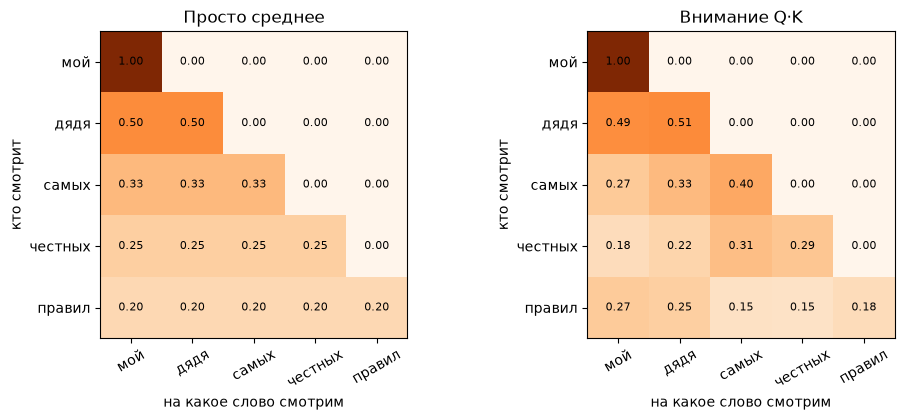

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, w, title in [(axes[0], weights_avg, "Просто среднее"), (axes[1], weights.detach(), "Внимание Q·K")]:
    ax.imshow(w, cmap="Oranges", vmin=0, vmax=1)
    for i in range(T):
        for j in range(T):
            ax.text(j, i, f"{w[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(T), words, rotation=30)
    ax.set_yticks(range(T), words)
    ax.set_xlabel("на какое слово смотрим")
    ax.set_ylabel("кто смотрит")
    ax.set_title(title)
plt.tight_layout()
plt.savefig("attention_weights.png", dpi=100)
show()

## 6. Внимание, настроенное вручную

Пусть вектор слова говорит, какая это часть речи, а запрос и ключ — это сам вектор.
Тогда «честных» найдёт среди прошлых слов другое прилагательное «самых», а «правил» — существительное «дядя».
Обученная модель сама подбирает такие Q и K, чтобы находить нужное: подходящую рифму, начало слова, открытую кавычку.

In [6]:
# --- 3. Внимание, настроенное вручную: слово ищет похожие на себя слова
# Вектор слова — «какая это часть речи». Пусть запрос = ключ = этот вектор:
# тогда скалярное произведение велико у похожих слов, и они получат большой вес.
x_toy = torch.tensor([
    # местоим. сущ. прилаг.
    [1.0, 0.0, 0.0],   # мой
    [0.0, 1.0, 0.0],   # дядя
    [0.0, 0.0, 1.0],   # самых
    [0.0, 0.0, 1.0],   # честных
    [0.0, 1.0, 0.0],   # правил (здесь считаем его похожим на существительное)
]) * 3
w_toy = torch.softmax((x_toy @ x_toy.T).masked_fill(mask == 0, float("-inf")), dim=1)
print("Веса «ищу похожих»:")
print(w_toy.round(decimals=2))
for i in range(1, T):
    j = w_toy[i, :i].argmax().item()
    if w_toy[i, j] > 0.1:
        print(f"«{words[i]}» из предыдущих слов больше всего смотрит на «{words[j]}» ({w_toy[i, j]:.2f})")
    else:
        print(f"«{words[i]}»: похожих слов раньше не было — смотрит только на себя")

Веса «ищу похожих»:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 1.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 1.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.5000, 0.5000, 0.0000],
        [0.0000, 0.5000, 0.0000, 0.0000, 0.5000]])
«дядя»: похожих слов раньше не было — смотрит только на себя
«самых»: похожих слов раньше не было — смотрит только на себя
«честных» из предыдущих слов больше всего смотрит на «самых» (0.50)
«правил» из предыдущих слов больше всего смотрит на «дядя» (0.50)


## 7. Внимание не знает порядка

Внимание смотрит на **набор** предыдущих слов, а не на их очередь: веса зависят только от того, *какие* это слова.
Перемешаем первые четыре слова — выход для последнего слова «правил» не изменится ни на капельку.

Но для языка порядок важен: «мама мыла раму» ≠ «раму мыла мама». Поэтому в GPT к эмбеддингу каждого символа
добавляют ещё **эмбеддинг его места** (`pos_emb` в `MiniGPT`) — и тогда одно и то же слово в начале и в конце строки выглядит для внимания по-разному.

In [7]:
def attend(x):
    """Внимание с маской на слоях to_q, to_k, to_v из части 2."""
    return F.scaled_dot_product_attention(to_q(x)[None], to_k(x)[None], to_v(x)[None], is_causal=True)[0]


# Внимание не знает порядка слов: перемешаем первые четыре — выход последнего слова не изменится
order = [3, 0, 2, 1, 4]
print("Было:  ", " ".join(words))
print("Стало: ", " ".join(words[i] for i in order))
print("Выход для «правил» тот же:", torch.allclose(attend(x)[-1], attend(x[order])[-1], atol=1e-6))
print("Поэтому в GPT (шаг 6) к каждому токену добавляют ещё и эмбеддинг его места — pos_emb")

Было:   мой дядя самых честных правил
Стало:  честных мой самых дядя правил
Выход для «правил» тот же: True
Поэтому в GPT (шаг 6) к каждому токену добавляют ещё и эмбеддинг его места — pos_emb


## 8. Несколько голов

Числа каждого токена делим на 4 части — у каждой головы своя часть, и внимание считается для всех голов сразу.
Потом результаты склеиваются обратно. Так устроен класс `SelfAttention` в `common.py`.

In [8]:
# --- 4. Несколько голов: несколько независимых «взглядов» сразу
n_head, C_big = 4, 16
x_big = torch.randn(1, T, C_big)
qkv = nn.Linear(C_big, 3 * C_big)(x_big)
q, k, v = qkv.split(C_big, dim=2)
q, k, v = (t.view(1, T, n_head, C_big // n_head).transpose(1, 2) for t in (q, k, v))
print("Q для 4 голов:", tuple(q.shape), "= (пример, головы, токены, числа на голову)")
out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
print("Выход голов:", tuple(out.shape), "→ склеиваем обратно:", tuple(out.transpose(1, 2).reshape(1, T, C_big).shape))

Q для 4 голов: (1, 4, 5, 4) = (пример, головы, токены, числа на голову)
Выход голов: (1, 4, 5, 4) → склеиваем обратно: (1, 5, 16)


## Попробуйте сами

1. В пункте 2 поменяйте запрос на `(0, 1)`. Какое слово теперь получит самый большой вес и каким станет выход? Посчитайте сначала в уме.
2. Уберите маску (`masked_fill`) в пункте 3. Как изменилась картинка весов? Почему такая модель «жульничает» при обучении?
3. В пункте 6 сделайте «правил» прилагательным `[0, 0, 1]`. На кого оно теперь смотрит?
4. Уберите `* 3` у `x_toy`. Почему веса стали менее «уверенными»? (Подсказка: температура из шага 4.)
5. В пункте 7 поменяйте местами последнее слово с другим (`order = [4, 1, 2, 3, 0]`). Совпадёт ли теперь выход? Почему?